# GABLS4 LES Intercomparison Study for Stable Boundary Layers: Vertical Cross-Sectional Views

In [1]:
from IPython.display import display, Markdown
from datetime import datetime, timezone
display(Markdown(f"*Last run: {datetime.now(timezone.utc).strftime('%B %d, %Y at %H:%M UTC')}*"))

*Last run: November 01, 2026 at 02:15 UTC*

**Case Description:** This notebook shows vertical (x-z and y-z plane) cross-sections of the velocity components ($u$, $v$, $w$) and potential temperature ($\theta$) from the GABLS4 extremely stable boundary-layer benchmark at Dome C, Antarctica. The x-z slices are extracted at three spanwise locations ($0.25\,L_y$, $0.5\,L_y$, $0.75\,L_y$); the y-z slice is extracted at $0.5\,L_x$. The 3D fields are sampled at the configured final time from `Config.py` using the reference run `256x256x256_LASDD_SM_SP`.

**Load the necessary packages**

In [2]:
import os
import re
import glob
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

**Input & Output Directories**

In [3]:
# Base directory (jaxalfa/)
from pathlib import Path

def find_repo_root(start=None):
    path = Path(start or ('__file__' in globals() and __file__) or Path.cwd()).resolve()
    for candidate in (path, *path.parents):
        if (candidate / 'examples').is_dir() and (candidate / 'docs').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate jaxalfa repository root')

BaseDir = find_repo_root()

# Results tree: 'examples' (DGX, A100), 'examples_A6000ada' (HAL, RTX 6000 Ada),
# 'examples_H100' (Empire AI, H100)
Platform = 'examples_A6000ada'

# Reference run: 256x256x256 LASDD-SM single precision
RunDir    = BaseDir / Platform / 'SBL_GABLS4/runs/256x256x256_LASDD_SM_SP'
OutputDir = RunDir / 'output'

cfg = {}
exec((RunDir / 'Config.py').read_text(), cfg)

**Load 3D fields from the configured final time**

In [4]:
T_snapshot = float(cfg['SimTime'])  # unit: sec
dt = float(cfg['dt'])
iter_3D = int(T_snapshot / dt)
field_path = OutputDir / f'ALFA_3DFields_Iteration_{iter_3D}.npz'

if field_path.exists():
    File3D = np.load(field_path)
    u3D  = File3D['u']
    v3D  = File3D['v']
    w3D  = File3D['w']
    TH3D = File3D['TH']
else:
    nx = int(cfg['nx']); ny = int(cfg['ny']); nz = int(cfg['nz'])
    print(f'Missing {field_path}; plotting NaN placeholders for this run.')
    u3D = np.full((nx, ny, nz), np.nan)
    v3D = np.full((nx, ny, nz), np.nan)
    w3D = np.full((nx, ny, nz), np.nan)
    TH3D = np.full((nx, ny, nz), np.nan)

**Input Information from the Config File**

In [5]:
l_x = float(cfg['l_x'])
l_y = float(cfg['l_y'])
l_z = float(cfg['l_z'])
z_damping = float(cfg.get('z_damping', np.nan))
SimTime = float(cfg['SimTime'])

nx = int(cfg['nx'])
ny = int(cfg['ny'])
nz = int(cfg['nz'])
dx = l_x / nx
dy = l_y / ny
dz = l_z / (nz - 1)
x_axis = dx * np.arange(nx)
y_axis = dy * np.arange(ny)

**Derived Variables**

In [6]:
# Half levels for u, v, TH variables
z_u = np.array([(k + 0.5) * l_z / (nz - 1) for k in range(nz)])

# Full levels for w
z_w = np.array([k * l_z / (nz - 1) for k in range(nz)])

**Plot vertical (x-z) cross-section of longitudinal velocity fields**

The start of the damping layer is shown by dotted lines.

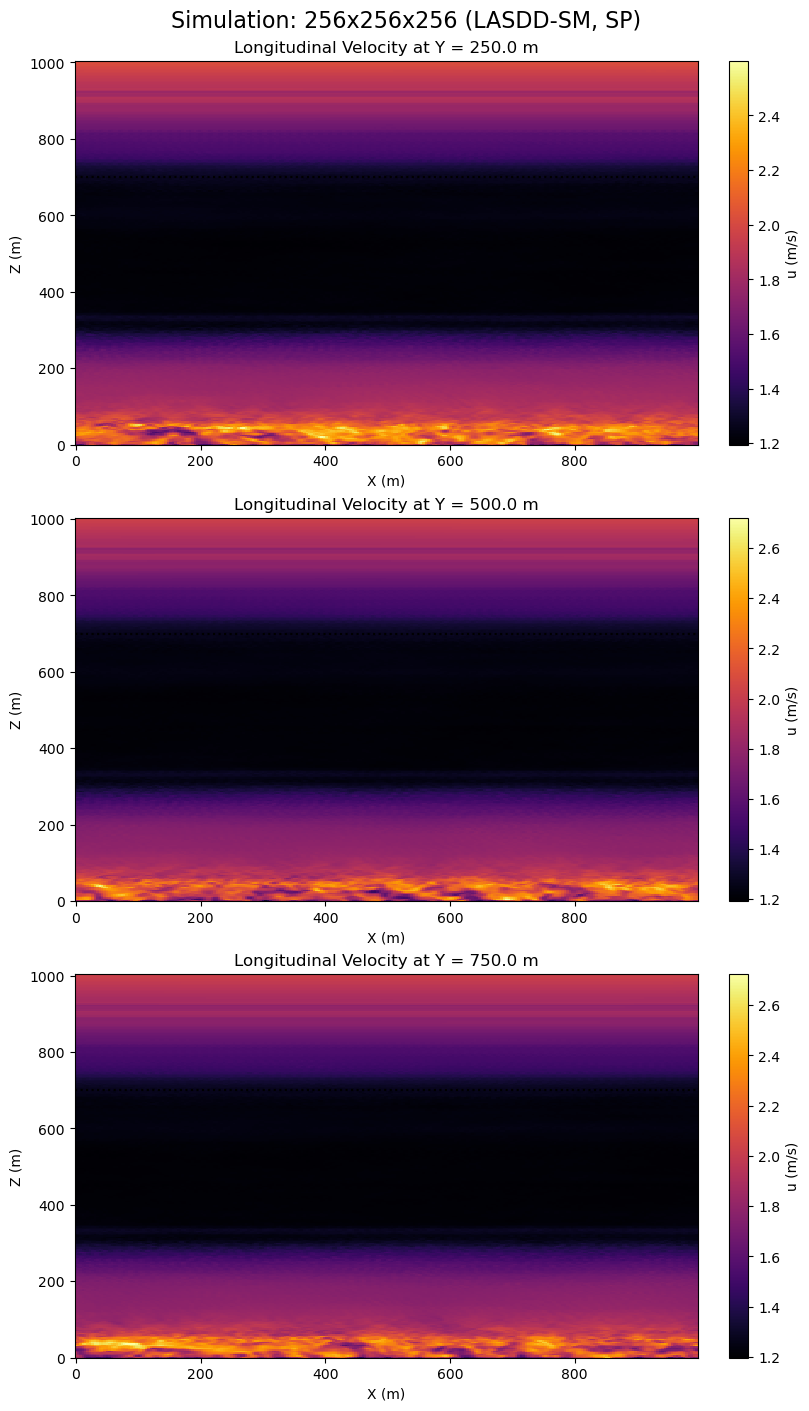

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14), constrained_layout=True)

# Selected cross-sections at 0.25*l_y, 0.5*l_y, and 0.75*l_y
j_levels = [int(ny/4), int(ny/2), int(ny*3/4)]

for i, j in enumerate(j_levels):
    im = axes[i].pcolor(x_axis, z_u, u3D[:,j,:].T, cmap='inferno')
    axes[i].set_title(f'Longitudinal Velocity at Y = {j * dy:.1f} m',
                      fontsize=12)
    axes[i].set_xlabel('X (m)')
    axes[i].set_ylabel('Z (m)')
    axes[i].set_aspect('auto')
    axes[i].axhline(y=z_damping, color='k', linestyle=':', linewidth=1.5)
    fig.colorbar(im, ax=axes[i], label='u (m/s)')

plt.suptitle('Simulation: 256x256x256 (LASDD-SM, SP)', fontsize=16)
plt.show()

**Plot vertical (x-z) cross-section of lateral velocity fields**

The start of the damping layer is shown by dotted lines.

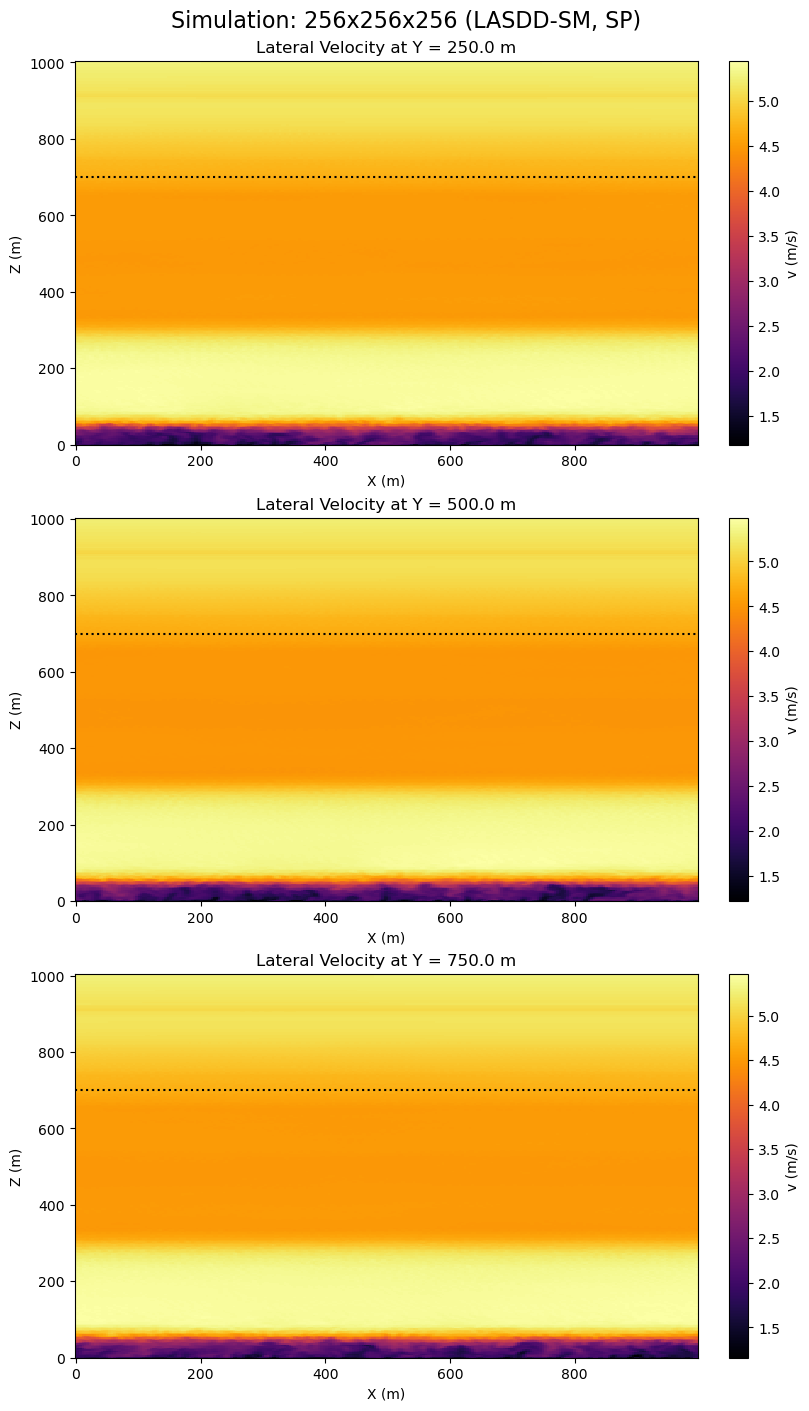

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14), constrained_layout=True)

# Selected cross-sections at 0.25*l_y, 0.5*l_y, and 0.75*l_y
j_levels = [int(ny/4), int(ny/2), int(ny*3/4)]

for i, j in enumerate(j_levels):
    im = axes[i].pcolor(x_axis, z_u, v3D[:,j,:].T, cmap='inferno')
    axes[i].set_title(f'Lateral Velocity at Y = {j * dy:.1f} m',
                      fontsize=12)
    axes[i].set_xlabel('X (m)')
    axes[i].set_ylabel('Z (m)')
    axes[i].set_aspect('auto')
    axes[i].axhline(y=z_damping, color='k', linestyle=':', linewidth=1.5)
    fig.colorbar(im, ax=axes[i], label='v (m/s)')

plt.suptitle('Simulation: 256x256x256 (LASDD-SM, SP)', fontsize=16)
plt.show()

**Plot vertical (x-z) cross-section of vertical velocity fields**

The start of the damping layer is shown by dotted lines.

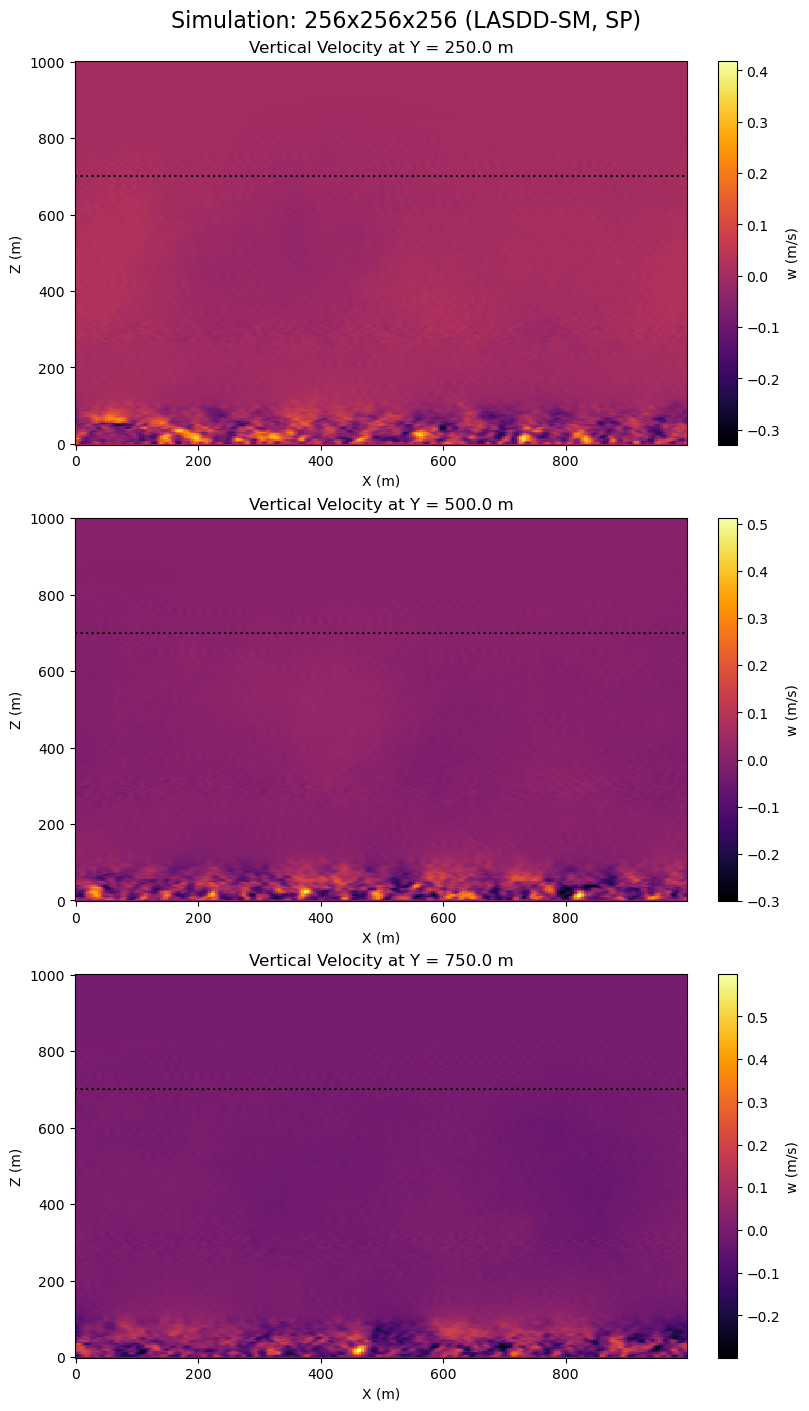

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14), constrained_layout=True)

# Selected cross-sections at 0.25*l_y, 0.5*l_y, and 0.75*l_y
j_levels = [int(ny/4), int(ny/2), int(ny*3/4)]

for i, j in enumerate(j_levels):
    im = axes[i].pcolor(x_axis, z_w, w3D[:,j,:].T, cmap='inferno')
    axes[i].set_title(f'Vertical Velocity at Y = {j * dy:.1f} m',
                      fontsize=12)
    axes[i].set_xlabel('X (m)')
    axes[i].set_ylabel('Z (m)')
    axes[i].set_aspect('auto')
    axes[i].axhline(y=z_damping, color='k', linestyle=':', linewidth=1.5)
    fig.colorbar(im, ax=axes[i], label='w (m/s)')

plt.suptitle('Simulation: 256x256x256 (LASDD-SM, SP)', fontsize=16)
plt.show()

**Plot vertical (x-z) cross-section of potential temperature fields**

The start of the damping layer is shown by dotted lines.

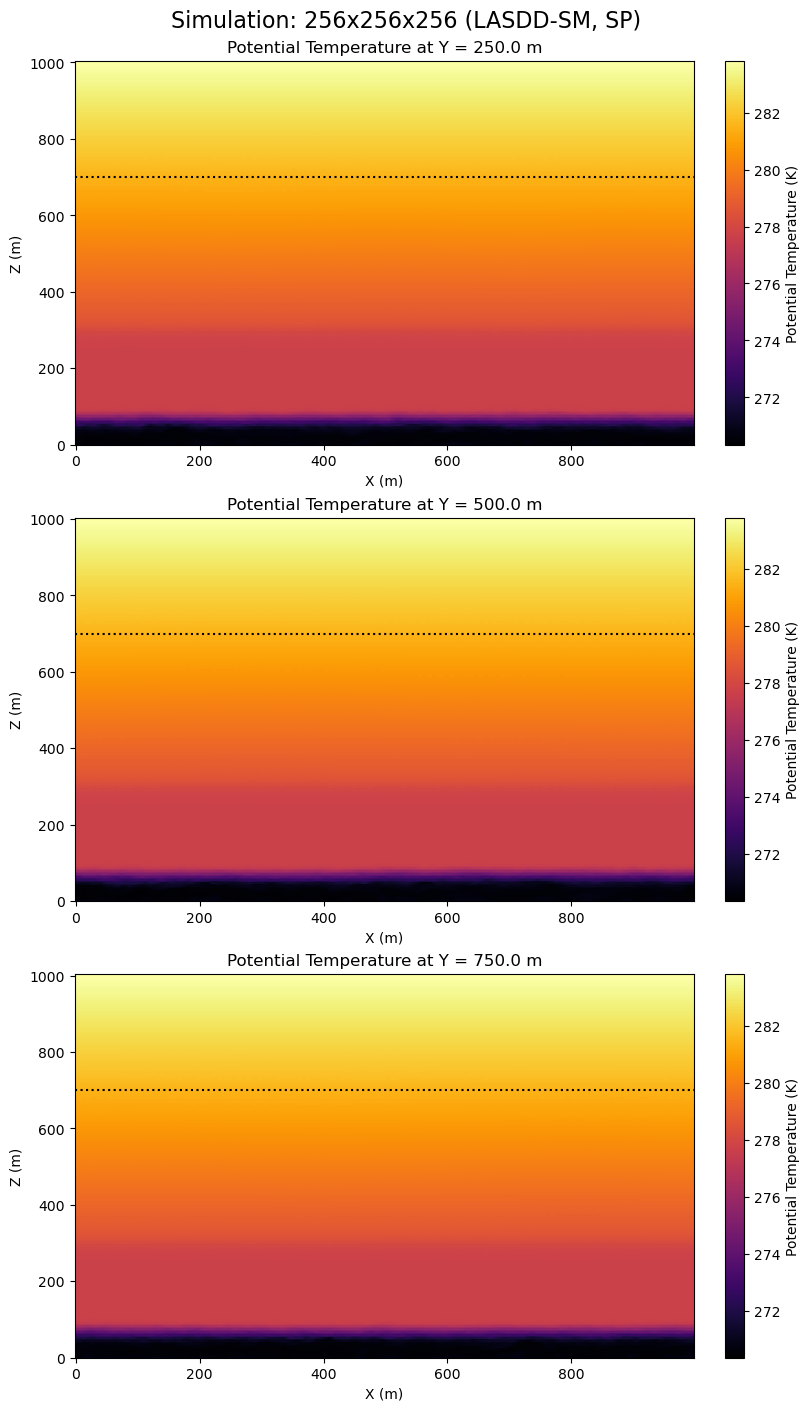

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(8, 14), constrained_layout=True)

# Selected cross-sections at 0.25*l_y, 0.5*l_y, and 0.75*l_y
j_levels = [int(ny/4), int(ny/2), int(ny*3/4)]

for i, j in enumerate(j_levels):
    im = axes[i].pcolor(x_axis, z_u, TH3D[:,j,:].T, cmap='inferno')
    axes[i].set_title(f'Potential Temperature at Y = {j * dy:.1f} m',
                      fontsize=12)
    axes[i].set_xlabel('X (m)')
    axes[i].set_ylabel('Z (m)')
    axes[i].set_aspect('auto')
    axes[i].axhline(y=z_damping, color='k', linestyle=':', linewidth=1.5)
    fig.colorbar(im, ax=axes[i], label='Potential Temperature (K)')

plt.suptitle('Simulation: 256x256x256 (LASDD-SM, SP)', fontsize=16)
plt.show()

**Plot vertical (y-z) cross-section at $X = 0.5\,L_x$**

The start of the damping layer is shown by dotted lines.

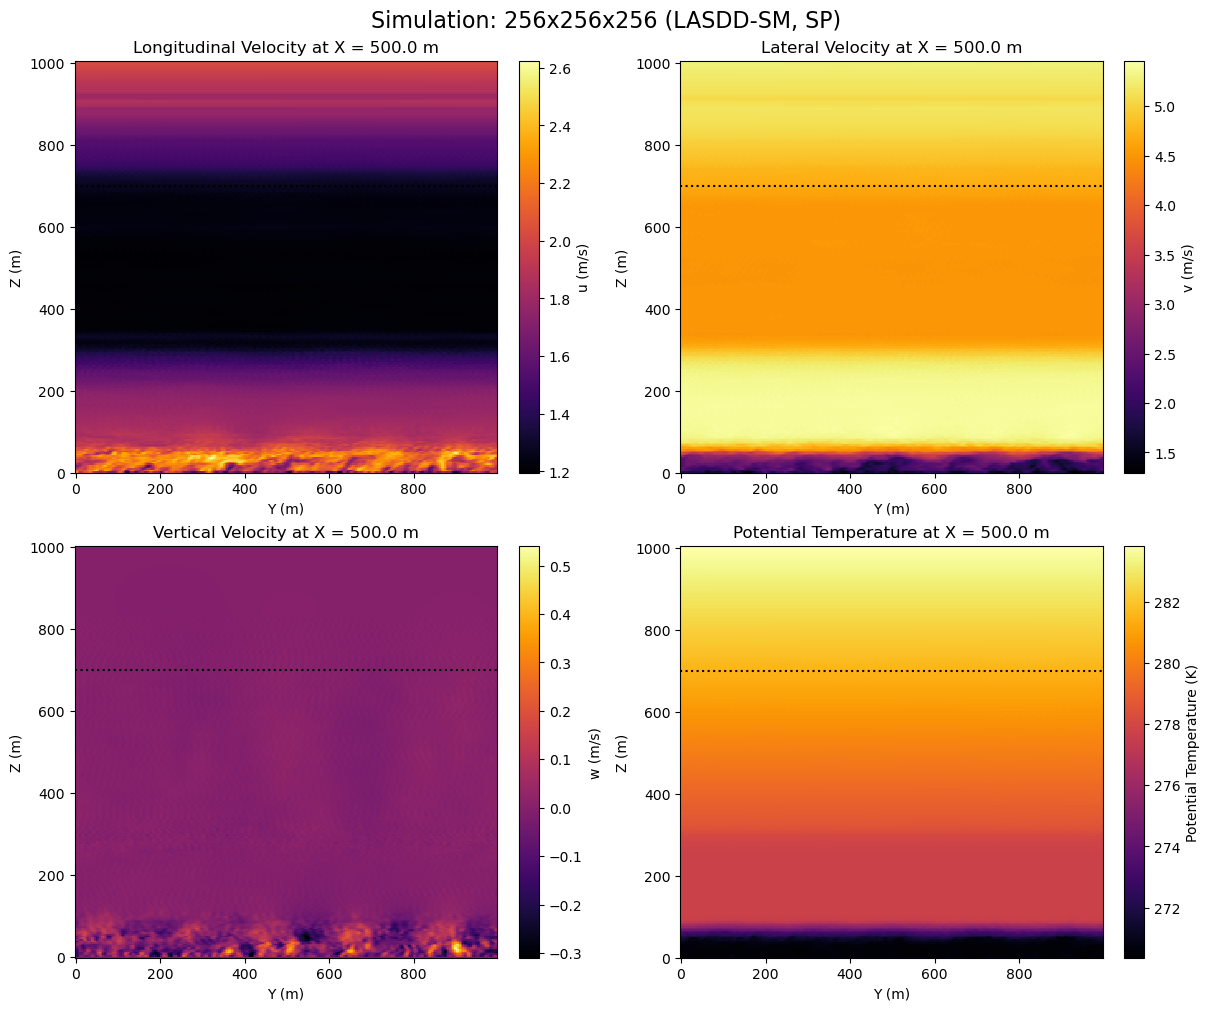

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
axes = axes.flatten()

# y-z slice at mid-domain in x
i_slice = int(nx/2)

fields = [
    (u3D[i_slice,:,:].T,  z_u, 'Longitudinal Velocity', 'u (m/s)'),
    (v3D[i_slice,:,:].T,  z_u, 'Lateral Velocity',      'v (m/s)'),
    (w3D[i_slice,:,:].T,  z_w, 'Vertical Velocity',     'w (m/s)'),
    (TH3D[i_slice,:,:].T, z_u, 'Potential Temperature', 'Potential Temperature (K)'),
]

for ax, (field, z_axis, title, clabel) in zip(axes, fields):
    im = ax.pcolor(y_axis, z_axis, field, cmap='inferno')
    ax.set_title(f'{title} at X = {i_slice * dx:.1f} m', fontsize=12)
    ax.set_xlabel('Y (m)')
    ax.set_ylabel('Z (m)')
    ax.set_aspect('auto')
    ax.axhline(y=z_damping, color='k', linestyle=':', linewidth=1.5)
    fig.colorbar(im, ax=ax, label=clabel)

plt.suptitle('Simulation: 256x256x256 (LASDD-SM, SP)', fontsize=16)
plt.show()